# Flavor Profile vs Sentiment Analysis (CORRECTED)

This notebook analyzes:
1. Sweet Level vs Sentiment (review-level and product-level)
2. Iced Level vs Sentiment (review-level and product-level)
3. Combined effects of sweet and iced on sentiment

**Key Correction**: Uses actual sentiment labels (positive/neutral/negative) instead of treating confidence scores as sentiment polarity.
- **Sentiment Score** = confidence of the prediction (used for filtering only)
- **Sentiment Label** = actual sentiment (positive/neutral/negative) - used for analysis

In [32]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

# Add parent directories to path for imports
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

# Set plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

## 1. Load Data

In [33]:
# Load the sentiment data
df = pd.read_csv('results/getpop_sentiment_reviews.csv')
df = df[df['verified']]

# Fill missing flavor levels
# If sweet_level is not null AND iced_level is null -> set iced_level to 0
df.loc[df['sweet_level'].notna() & df['iced_level'].isna(), 'iced_level'] = 0

# If iced_level is not null AND sweet_level is null -> set sweet_level to 0
df.loc[df['iced_level'].notna() & df['sweet_level'].isna(), 'sweet_level'] = 0

df.loc[df['iced_level'].notna(), 'iced_level'] += 1
df.loc[df['sweet_level'].notna(), 'sweet_level'] += 1

# Create numeric sentiment variable for correlation analysis
# positive=1, neutral=0, negative=-1
sentiment_map = {'positive': 1, 'neutral': 0, 'negative': -1}
df['sentiment_numeric'] = df['Sentiment'].map(sentiment_map)

print(f"Total reviews: {len(df)}")
print(f"Reviews with verified=True: {df['verified'].sum()}")
print(f"Reviews with ratings: {df['rating'].notna().sum()}")
print(f"Reviews with sweet_level: {df['sweet_level'].notna().sum()}")
print(f"Reviews with iced_level: {df['iced_level'].notna().sum()}")
print(f"Reviews with both sweet and iced: {(df['sweet_level'].notna() & df['iced_level'].notna()).sum()}")
print(f"\nSentiment confidence score range: {df['Sentiment Score'].min():.3f} to {df['Sentiment Score'].max():.3f}")
print(f"Mean confidence: {df['Sentiment Score'].mean():.3f}")

df.head()

Total reviews: 2927
Reviews with verified=True: 2927
Reviews with ratings: 2927
Reviews with sweet_level: 2410
Reviews with iced_level: 2410
Reviews with both sweet and iced: 2410

Sentiment confidence score range: 0.376 to 0.991
Mean confidence: 0.753


,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified,sentiment_numeric
0,raz-ca6000-alaskan-mint,5.000,5.000,1.000,neutral,0.594,GETPOP,Way too sweet,1769,318,True,0
1,hyppe-max-flow-aloe-grape,4.000,4.000,5.000,positive,0.617,GETPOP,Great flavor,1771,10175,True,1
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.000,neutral,0.398,GETPOP,Perfect,1771,10174,True,0
3,hyppe-max-flow-aloe-grape,1.000,5.000,5.000,neutral,0.536,GETPOP,Wonderful,1771,10173,True,0
4,hyde-edge-recharge-aloe-grape,3.000,3.000,4.000,neutral,0.539,GETPOP,Nice smooth flavor,1773,10128,True,0


## 2. Review-Level Analysis: Sweet Level vs Sentiment

In [34]:
# Filter to reviews with sweet_level
df_sweet = df[df['sweet_level'].notna()].copy()

print(f"\n{'='*70}")
print("REVIEW-LEVEL: Sweet Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total reviews with sweet_level: {len(df_sweet)}")
print(f"\nSweet Level Distribution:")
print(df_sweet['sweet_level'].value_counts().sort_index())
print(f"\nSentiment Distribution:")
counts = df_sweet['Sentiment'].value_counts()
percentages = df_sweet['Sentiment'].value_counts(normalize=True) * 100

result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})
print(result)


REVIEW-LEVEL: Sweet Level vs Sentiment Analysis
Total reviews with sweet_level: 2410

Sweet Level Distribution:
sweet_level
1.000     76
2.000    194
3.000    634
4.000    759
5.000    747
Name: count, dtype: int64

Sentiment Distribution:
           Count  Percentage (%)
Sentiment                       
positive    1603          66.510
neutral      716          29.710
negative      91           3.780


In [35]:
# Calculate sentiment metrics by sweet level (CORRECTED)
sweet_sentiment = df_sweet.groupby('sweet_level').agg({
    'sentiment_numeric': ['mean', 'std'],  # Numeric sentiment for correlation
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100,  # % positive
    'Review': 'count',
    'rating': 'mean',
    'Sentiment Score': 'mean'  # Average confidence (for reference only)
}).round(3)

sweet_sentiment.columns = ['Sentiment_Numeric_Mean', 'Sentiment_Numeric_Std', 
                           'Percent_Positive', 'Review_Count', 'Rating_Mean', 
                           'Avg_Confidence']
print("\nSweet Level vs Sentiment Metrics:")
print(sweet_sentiment)
print("\nNote: Sentiment_Numeric_Mean ranges from -1 (all negative) to +1 (all positive), 0 = all neutral")
print("      Avg_Confidence is the mean prediction confidence (not sentiment polarity)")


Sweet Level vs Sentiment Metrics:
             Sentiment_Numeric_Mean  Sentiment_Numeric_Std  Percent_Positive  \
sweet_level                                                                    
1.000                         0.382                  0.692            50.000   
2.000                         0.459                  0.676            56.186   
3.000                         0.601                  0.576            64.669   
4.000                         0.680                  0.523            70.751   
5.000                         0.665                  0.505            68.139   

             Review_Count  Rating_Mean  Avg_Confidence  
sweet_level                                             
1.000                  76        4.447           0.754  
2.000                 193        4.490           0.750  
3.000                 634        4.737           0.760  
4.000                 758        4.819           0.761  
5.000                 747        4.878           0.747  

Note

In [36]:
# Statistical test: correlation (CORRECTED - using numeric sentiment, not confidence score)
corr_sweet_sentiment = df_sweet[['sweet_level', 'sentiment_numeric']].corr()
print("\nCorrelation Matrix (Sweet Level vs Sentiment):")
print(corr_sweet_sentiment)

# Pearson correlation with p-value
corr_coef, p_value = stats.pearsonr(df_sweet['sweet_level'], df_sweet['sentiment_numeric'])
print(f"\nPearson Correlation (Sweet vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")
print(f"\nInterpretation: {'Positive' if corr_coef > 0 else 'Negative'} correlation - "
      f"{'higher' if corr_coef > 0 else 'lower'} sweet levels associate with "
      f"{'more positive' if corr_coef > 0 else 'more negative'} sentiment")


Correlation Matrix (Sweet Level vs Sentiment):
                   sweet_level  sentiment_numeric
sweet_level              1.000              0.117
sentiment_numeric        0.117              1.000

Pearson Correlation (Sweet vs Sentiment): 0.1166
P-value: 9.3099e-09
Significant at α=0.05: Yes

Interpretation: Positive correlation - higher sweet levels associate with more positive sentiment


In [37]:
# Chi-square test for independence (categorical analysis)
contingency_table = pd.crosstab(df_sweet['sweet_level'], df_sweet['Sentiment'])
chi2, p_chi, dof, expected = chi2_contingency(contingency_table)

print("\nChi-Square Test (Sweet Level vs Sentiment Categories):")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_chi:.4e}")
print(f"Degrees of freedom: {dof}")
print(f"Significant at α=0.05: {'Yes' if p_chi < 0.05 else 'No'}")


Chi-Square Test (Sweet Level vs Sentiment Categories):
Chi-square statistic: 62.0877
P-value: 1.8122e-10
Degrees of freedom: 8
Significant at α=0.05: Yes


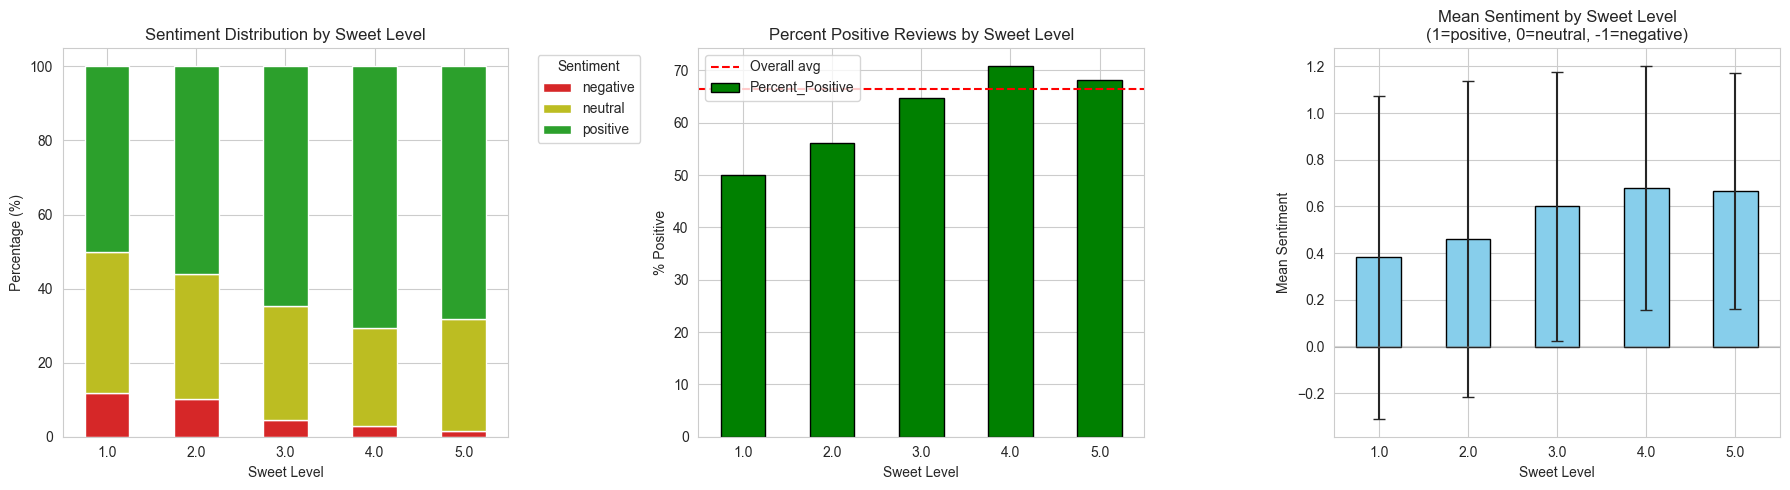

In [38]:
# Visualizations (CORRECTED - using sentiment labels, not confidence)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sentiment distribution by sweet level
sentiment_by_sweet = pd.crosstab(df_sweet['sweet_level'], df_sweet['Sentiment'], normalize='index') * 100
sentiment_by_sweet.plot(kind='bar', stacked=True, ax=axes[0],
                        color=['#d62728', '#bcbd22', '#2ca02c'])
axes[0].set_title('Sentiment Distribution by Sweet Level')
axes[0].set_xlabel('Sweet Level')
axes[0].set_ylabel('Percentage (%)')
axes[0].legend(title='Sentiment', bbox_to_anchor=(1.05, 1))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

# Percent positive by sweet level
sweet_sentiment.reset_index().plot(x='sweet_level', y='Percent_Positive', 
                                   kind='bar', ax=axes[1],
                                   color='green', edgecolor='black', legend=False)
axes[1].set_title('Percent Positive Reviews by Sweet Level')
axes[1].set_xlabel('Sweet Level')
axes[1].set_ylabel('% Positive')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].axhline(y=df_sweet['Sentiment'].eq('positive').mean()*100, 
                color='red', linestyle='--', label='Overall avg')
axes[1].legend()

# Numeric sentiment mean by sweet level
sweet_sentiment.reset_index().plot(x='sweet_level', y='Sentiment_Numeric_Mean',
                                   yerr='Sentiment_Numeric_Std', kind='bar', ax=axes[2],
                                   capsize=4, color='skyblue', edgecolor='black', legend=False)
axes[2].set_title('Mean Sentiment by Sweet Level\n(1=positive, 0=neutral, -1=negative)')
axes[2].set_xlabel('Sweet Level')
axes[2].set_ylabel('Mean Sentiment')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].axhline(y=0, color='gray', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Review-Level Analysis: Iced Level vs Sentiment

In [39]:
# Filter to reviews with iced_level
df_iced = df[df['iced_level'].notna()].copy()

print(f"\n{'='*70}")
print("REVIEW-LEVEL: Iced Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total reviews with iced_level: {len(df_iced)}")
print(f"\nIced Level Distribution:")
print(df_iced['iced_level'].value_counts().sort_index())
print(f"\nSentiment Distribution:")

counts = df_iced['Sentiment'].value_counts()
percentages = df_iced['Sentiment'].value_counts(normalize=True) * 100

result = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})
print(result)


REVIEW-LEVEL: Iced Level vs Sentiment Analysis
Total reviews with iced_level: 2410

Iced Level Distribution:
iced_level
1.000    693
2.000    251
3.000    541
4.000    378
5.000    547
Name: count, dtype: int64

Sentiment Distribution:
           Count  Percentage (%)
Sentiment                       
positive    1603          66.510
neutral      716          29.710
negative      91           3.780


In [40]:
# Calculate sentiment metrics by iced level (CORRECTED)
iced_sentiment = df_iced.groupby('iced_level').agg({
    'sentiment_numeric': ['mean', 'std'],
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100,
    'Review': 'count',
    'rating': 'mean',
    'Sentiment Score': 'mean'
}).round(3)

iced_sentiment.columns = ['Sentiment_Numeric_Mean', 'Sentiment_Numeric_Std',
                          'Percent_Positive', 'Review_Count', 'Rating_Mean',
                          'Avg_Confidence']
print("\nIced Level vs Sentiment Metrics:")
print(iced_sentiment)


Iced Level vs Sentiment Metrics:
            Sentiment_Numeric_Mean  Sentiment_Numeric_Std  Percent_Positive  \
iced_level                                                                    
1.000                        0.688                  0.514            71.284   
2.000                        0.574                  0.584            62.151   
3.000                        0.582                  0.589            63.401   
4.000                        0.624                  0.561            66.402   
5.000                        0.622                  0.552            65.631   

            Review_Count  Rating_Mean  Avg_Confidence  
iced_level                                             
1.000                693        4.827           0.781  
2.000                251        4.606           0.737  
3.000                541        4.708           0.759  
4.000                376        4.788           0.747  
5.000                547        4.856           0.733  


In [41]:
# Statistical test: correlation (CORRECTED)
corr_iced_sentiment = df_iced[['iced_level', 'sentiment_numeric']].corr()
print("\nCorrelation Matrix (Iced Level vs Sentiment):")
print(corr_iced_sentiment)

# Pearson correlation with p-value
corr_coef, p_value = stats.pearsonr(df_iced['iced_level'], df_iced['sentiment_numeric'])
print(f"\nPearson Correlation (Iced vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")
print(f"\nInterpretation: {'Positive' if corr_coef > 0 else 'Negative'} correlation - "
      f"{'higher' if corr_coef > 0 else 'lower'} iced levels associate with "
      f"{'more positive' if corr_coef > 0 else 'more negative'} sentiment")


Correlation Matrix (Iced Level vs Sentiment):
                   iced_level  sentiment_numeric
iced_level              1.000             -0.038
sentiment_numeric      -0.038              1.000

Pearson Correlation (Iced vs Sentiment): -0.0385
P-value: 5.8858e-02
Significant at α=0.05: No

Interpretation: Negative correlation - lower iced levels associate with more negative sentiment


In [42]:
# Chi-square test
contingency_table = pd.crosstab(df_iced['iced_level'], df_iced['Sentiment'])
chi2, p_chi, dof, expected = chi2_contingency(contingency_table)

print("\nChi-Square Test (Iced Level vs Sentiment Categories):")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_chi:.4e}")
print(f"Degrees of freedom: {dof}")
print(f"Significant at α=0.05: {'Yes' if p_chi < 0.05 else 'No'}")


Chi-Square Test (Iced Level vs Sentiment Categories):
Chi-square statistic: 15.3202
P-value: 5.3210e-02
Degrees of freedom: 8
Significant at α=0.05: No


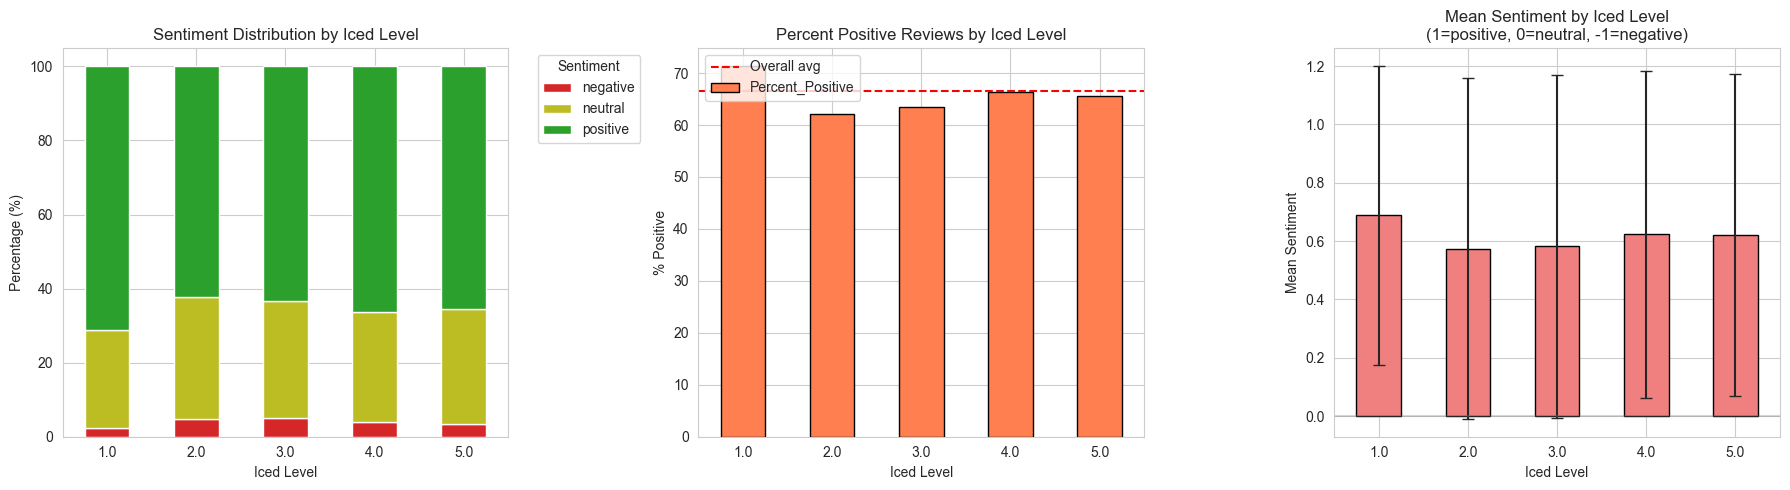

In [43]:
# Visualizations (CORRECTED)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sentiment distribution by iced level
sentiment_by_iced = pd.crosstab(df_iced['iced_level'], df_iced['Sentiment'], normalize='index') * 100
sentiment_by_iced.plot(kind='bar', stacked=True, ax=axes[0],
                       color=['#d62728', '#bcbd22', '#2ca02c'])
axes[0].set_title('Sentiment Distribution by Iced Level')
axes[0].set_xlabel('Iced Level')
axes[0].set_ylabel('Percentage (%)')
axes[0].legend(title='Sentiment', bbox_to_anchor=(1.05, 1))
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

# Percent positive by iced level
iced_sentiment.reset_index().plot(x='iced_level', y='Percent_Positive',
                                  kind='bar', ax=axes[1],
                                  color='coral', edgecolor='black', legend=False)
axes[1].set_title('Percent Positive Reviews by Iced Level')
axes[1].set_xlabel('Iced Level')
axes[1].set_ylabel('% Positive')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].axhline(y=df_iced['Sentiment'].eq('positive').mean()*100,
                color='red', linestyle='--', label='Overall avg')
axes[1].legend()

# Numeric sentiment mean by iced level
iced_sentiment.reset_index().plot(x='iced_level', y='Sentiment_Numeric_Mean',
                                  yerr='Sentiment_Numeric_Std', kind='bar', ax=axes[2],
                                  capsize=4, color='lightcoral', edgecolor='black', legend=False)
axes[2].set_title('Mean Sentiment by Iced Level\n(1=positive, 0=neutral, -1=negative)')
axes[2].set_xlabel('Iced Level')
axes[2].set_ylabel('Mean Sentiment')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].axhline(y=0, color='gray', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Product-Level Analysis: Sweet Level vs Sentiment

In [44]:
# Aggregate to product level for sweet (CORRECTED)
product_sweet = df_sweet.groupby('Product ID').agg({
    'sweet_level': 'mean',
    'sentiment_numeric': 'mean',  # Average numeric sentiment
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100,  # % positive
    'rating': 'mean',
    'Review': 'count',
    'Product': 'first',
    'Sentiment Score': 'mean'  # Average confidence
}).round(3)

product_sweet.columns = ['Sweet_Level_Avg', 'Sentiment_Numeric_Avg', 'Percent_Positive',
                         'Rating_Avg', 'Review_Count', 'Product_Name', 'Avg_Confidence']
product_sweet = product_sweet.reset_index()

print(f"\n{'='*70}")
print("PRODUCT-LEVEL: Sweet Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total products: {len(product_sweet)}")
print(f"\nProducts by review count:")
print(product_sweet['Review_Count'].describe())

product_sweet.head(10)


PRODUCT-LEVEL: Sweet Level vs Sentiment Analysis
Total products: 1081

Products by review count:
count   1081.000
mean       2.228
std        2.346
min        0.000
25%        1.000
50%        1.000
75%        2.000
max       21.000
Name: Review_Count, dtype: float64


,Product ID,Sweet_Level_Avg,Sentiment_Numeric_Avg,Percent_Positive,Rating_Avg,Review_Count,Product_Name,Avg_Confidence
0,1769,5.000,0.000,0.000,1.000,1,raz-ca6000-alaskan-mint,0.594
1,1771,4.500,0.500,50.000,5.000,2,hyppe-max-flow-aloe-grape,0.576
2,1773,3.000,0.000,0.000,4.000,1,hyde-edge-recharge-aloe-grape,0.539
3,1783,4.000,1.000,100.000,4.000,1,fume-ultra-apple-candy,0.974
4,1794,3.000,1.000,100.000,3.000,1,tyson-2-0-legend-30k-apple-melonberry,0.487
5,1814,3.000,1.000,100.000,5.000,1,geek-bar-pulse-x-25k-atl-mint,0.987
6,1819,5.000,0.000,0.000,5.000,1,geek-bar-pulse-15000-blow-pop-1,0.398
7,1822,3.333,0.667,66.667,4.667,6,hyde-edge-recharge-banana-ice,0.611
8,1830,4.000,0.600,60.000,5.000,5,hyde-edge-recharge-blueberry,0.584
9,1836,3.615,0.769,76.923,5.000,13,hyde-edge-recharge-cola-ice,0.845


In [45]:
# Correlation at product level (CORRECTED)
corr_product_sweet = product_sweet[['Sweet_Level_Avg', 'Sentiment_Numeric_Avg', 
                                     'Percent_Positive', 'Rating_Avg']].corr()
print("\nProduct-Level Correlation Matrix (Sweet):")
print(corr_product_sweet)

# Statistical test - numeric sentiment
corr_coef, p_value = stats.pearsonr(product_sweet['Sweet_Level_Avg'], 
                                      product_sweet['Sentiment_Numeric_Avg'])
print(f"\nPearson Correlation (Sweet vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")

# Statistical test - percent positive
corr_coef2, p_value2 = stats.pearsonr(product_sweet['Sweet_Level_Avg'],
                                        product_sweet['Percent_Positive'])
print(f"\nPearson Correlation (Sweet vs % Positive): {corr_coef2:.4f}")
print(f"P-value: {p_value2:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value2 < 0.05 else 'No'}")


Product-Level Correlation Matrix (Sweet):
                       Sweet_Level_Avg  Sentiment_Numeric_Avg  \
Sweet_Level_Avg                  1.000                  0.167   
Sentiment_Numeric_Avg            0.167                  1.000   
Percent_Positive                 0.112                  0.932   
Rating_Avg                       0.232                  0.408   

                       Percent_Positive  Rating_Avg  
Sweet_Level_Avg                   0.112       0.232  
Sentiment_Numeric_Avg             0.932       0.408  
Percent_Positive                  1.000       0.266  
Rating_Avg                        0.266       1.000  

Pearson Correlation (Sweet vs Sentiment): 0.1667
P-value: 3.5468e-08
Significant at α=0.05: Yes

Pearson Correlation (Sweet vs % Positive): 0.1124
P-value: 2.1422e-04
Significant at α=0.05: Yes


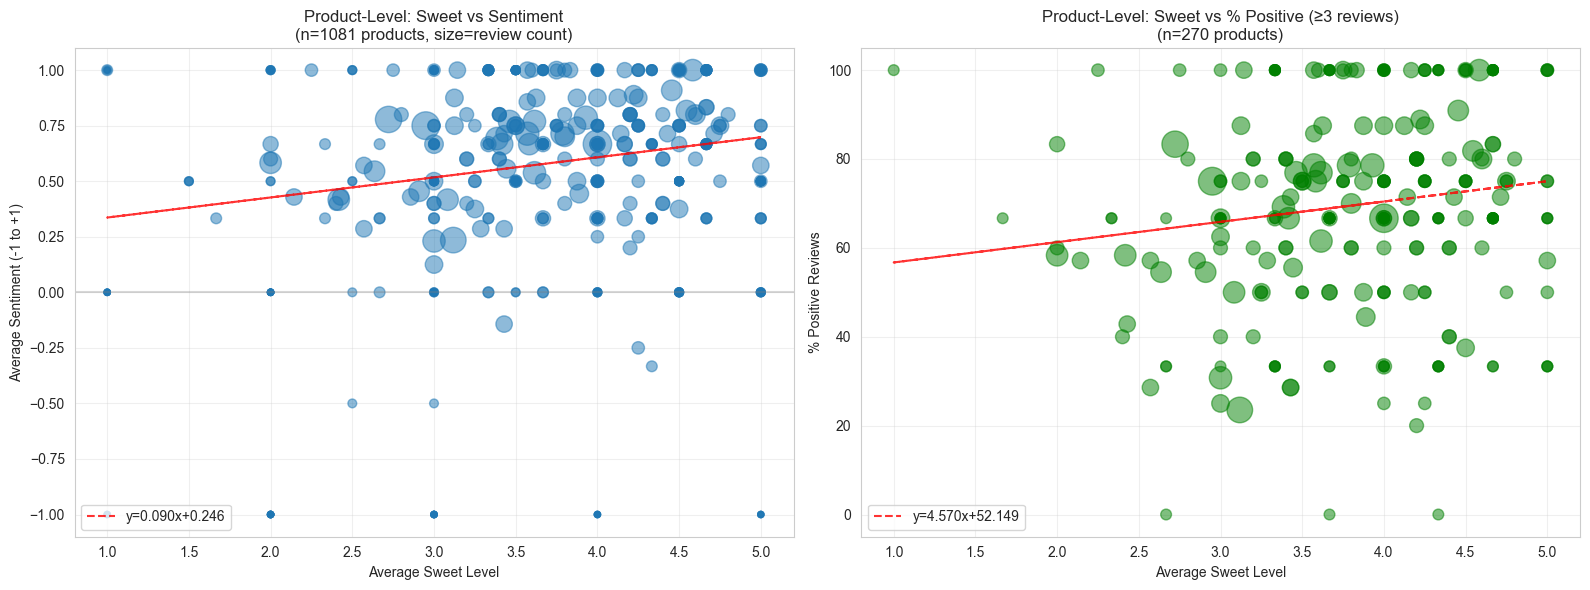


Filtered (≥3 reviews) Correlation: 0.1836, p=2.4594e-03


In [46]:
# Scatter plots (CORRECTED)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All products - numeric sentiment
axes[0].scatter(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Numeric_Avg'],
                alpha=0.5, s=product_sweet['Review_Count']*20)
axes[0].set_xlabel('Average Sweet Level')
axes[0].set_ylabel('Average Sentiment (-1 to +1)')
axes[0].set_title(f'Product-Level: Sweet vs Sentiment\n(n={len(product_sweet)} products, size=review count)')
# Add regression line
z = np.polyfit(product_sweet['Sweet_Level_Avg'], product_sweet['Sentiment_Numeric_Avg'], 1)
p = np.poly1d(z)
axes[0].plot(product_sweet['Sweet_Level_Avg'], p(product_sweet['Sweet_Level_Avg']),
             "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=0, color='gray', linestyle='-', alpha=0.3)

# Products with 3+ reviews - percent positive
product_sweet_filtered = product_sweet[product_sweet['Review_Count'] >= 3]
axes[1].scatter(product_sweet_filtered['Sweet_Level_Avg'], product_sweet_filtered['Percent_Positive'],
                alpha=0.5, s=product_sweet_filtered['Review_Count']*20, color='green')
axes[1].set_xlabel('Average Sweet Level')
axes[1].set_ylabel('% Positive Reviews')
axes[1].set_title(f'Product-Level: Sweet vs % Positive (≥3 reviews)\n(n={len(product_sweet_filtered)} products)')
if len(product_sweet_filtered) > 1:
    z = np.polyfit(product_sweet_filtered['Sweet_Level_Avg'], product_sweet_filtered['Percent_Positive'], 1)
    p = np.poly1d(z)
    axes[1].plot(product_sweet_filtered['Sweet_Level_Avg'], p(product_sweet_filtered['Sweet_Level_Avg']),
                 "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
    axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if len(product_sweet_filtered) > 1:
    corr_coef_filt, p_value_filt = stats.pearsonr(product_sweet_filtered['Sweet_Level_Avg'],
                                                    product_sweet_filtered['Sentiment_Numeric_Avg'])
    print(f"\nFiltered (≥3 reviews) Correlation: {corr_coef_filt:.4f}, p={p_value_filt:.4e}")

## 5. Product-Level Analysis: Iced Level vs Sentiment

In [47]:
# Aggregate to product level for iced (CORRECTED)
product_iced = df_iced.groupby('Product ID').agg({
    'iced_level': 'mean',
    'sentiment_numeric': 'mean',
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100,
    'rating': 'mean',
    'Review': 'count',
    'Product': 'first',
    'Sentiment Score': 'mean'
}).round(3)

product_iced.columns = ['Iced_Level_Avg', 'Sentiment_Numeric_Avg', 'Percent_Positive',
                        'Rating_Avg', 'Review_Count', 'Product_Name', 'Avg_Confidence']
product_iced = product_iced.reset_index()

print(f"\n{'='*70}")
print("PRODUCT-LEVEL: Iced Level vs Sentiment Analysis")
print(f"{'='*70}")
print(f"Total products: {len(product_iced)}")
print(f"\nProducts by review count:")
print(product_iced['Review_Count'].describe())

product_iced.head(10)


PRODUCT-LEVEL: Iced Level vs Sentiment Analysis
Total products: 1081

Products by review count:
count   1081.000
mean       2.228
std        2.346
min        0.000
25%        1.000
50%        1.000
75%        2.000
max       21.000
Name: Review_Count, dtype: float64


,Product ID,Iced_Level_Avg,Sentiment_Numeric_Avg,Percent_Positive,Rating_Avg,Review_Count,Product_Name,Avg_Confidence
0,1769,5.000,0.000,0.000,1.000,1,raz-ca6000-alaskan-mint,0.594
1,1771,2.500,0.500,50.000,5.000,2,hyppe-max-flow-aloe-grape,0.576
2,1773,3.000,0.000,0.000,4.000,1,hyde-edge-recharge-aloe-grape,0.539
3,1783,3.000,1.000,100.000,4.000,1,fume-ultra-apple-candy,0.974
4,1794,1.000,1.000,100.000,3.000,1,tyson-2-0-legend-30k-apple-melonberry,0.487
5,1814,3.000,1.000,100.000,5.000,1,geek-bar-pulse-x-25k-atl-mint,0.987
6,1819,1.000,0.000,0.000,5.000,1,geek-bar-pulse-15000-blow-pop-1,0.398
7,1822,3.667,0.667,66.667,4.667,6,hyde-edge-recharge-banana-ice,0.611
8,1830,2.400,0.600,60.000,5.000,5,hyde-edge-recharge-blueberry,0.584
9,1836,3.538,0.769,76.923,5.000,13,hyde-edge-recharge-cola-ice,0.845


In [48]:
# Correlation at product level (CORRECTED)
corr_product_iced = product_iced[['Iced_Level_Avg', 'Sentiment_Numeric_Avg',
                                   'Percent_Positive', 'Rating_Avg']].corr()
print("\nProduct-Level Correlation Matrix (Iced):")
print(corr_product_iced)

# Statistical test - numeric sentiment
corr_coef, p_value = stats.pearsonr(product_iced['Iced_Level_Avg'],
                                      product_iced['Sentiment_Numeric_Avg'])
print(f"\nPearson Correlation (Iced vs Sentiment): {corr_coef:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value < 0.05 else 'No'}")

# Statistical test - percent positive
corr_coef2, p_value2 = stats.pearsonr(product_iced['Iced_Level_Avg'],
                                        product_iced['Percent_Positive'])
print(f"\nPearson Correlation (Iced vs % Positive): {corr_coef2:.4f}")
print(f"P-value: {p_value2:.4e}")
print(f"Significant at α=0.05: {'Yes' if p_value2 < 0.05 else 'No'}")


Product-Level Correlation Matrix (Iced):
                       Iced_Level_Avg  Sentiment_Numeric_Avg  \
Iced_Level_Avg                  1.000                 -0.079   
Sentiment_Numeric_Avg          -0.079                  1.000   
Percent_Positive               -0.075                  0.932   
Rating_Avg                      0.026                  0.408   

                       Percent_Positive  Rating_Avg  
Iced_Level_Avg                   -0.075       0.026  
Sentiment_Numeric_Avg             0.932       0.408  
Percent_Positive                  1.000       0.266  
Rating_Avg                        0.266       1.000  

Pearson Correlation (Iced vs Sentiment): -0.0789
P-value: 9.4198e-03
Significant at α=0.05: Yes

Pearson Correlation (Iced vs % Positive): -0.0755
P-value: 1.3073e-02
Significant at α=0.05: Yes


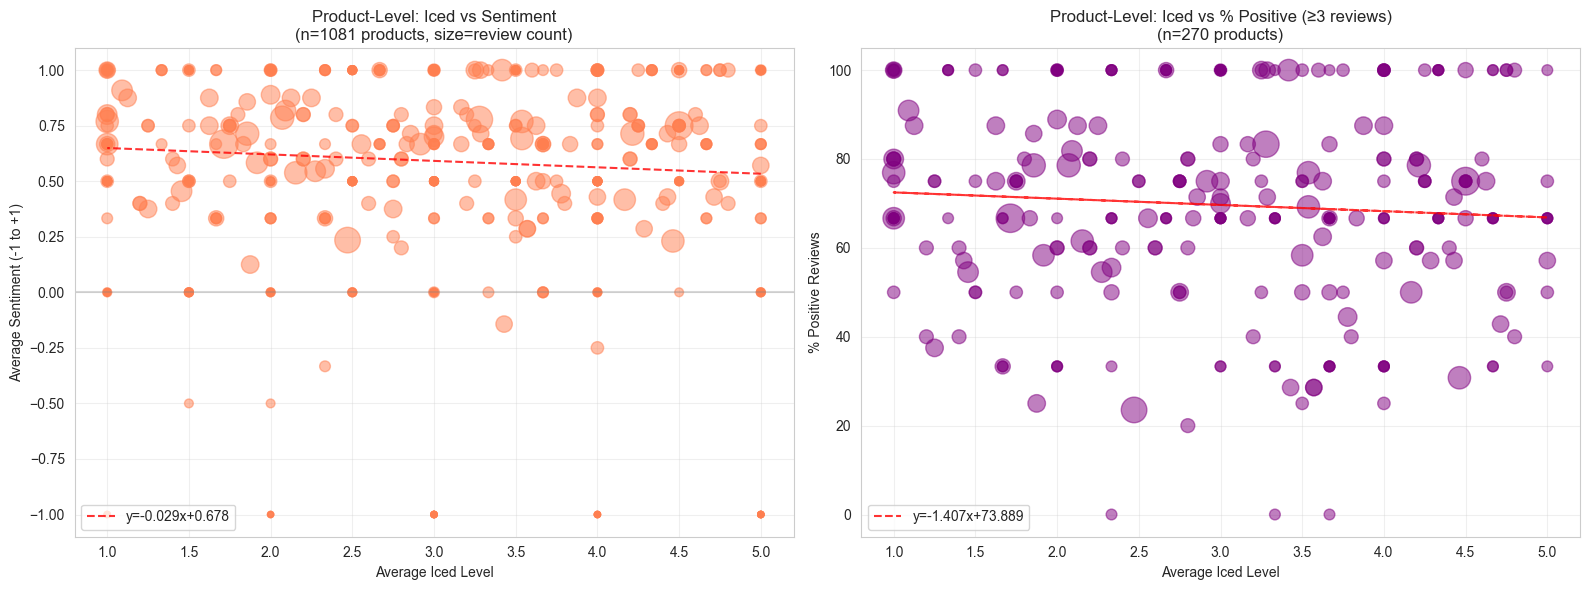


Filtered (≥3 reviews) Correlation: -0.0684, p=2.6305e-01


In [49]:
# Scatter plots (CORRECTED)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All products - numeric sentiment
axes[0].scatter(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Numeric_Avg'],
                alpha=0.5, s=product_iced['Review_Count']*20, color='coral')
axes[0].set_xlabel('Average Iced Level')
axes[0].set_ylabel('Average Sentiment (-1 to +1)')
axes[0].set_title(f'Product-Level: Iced vs Sentiment\n(n={len(product_iced)} products, size=review count)')
# Add regression line
z = np.polyfit(product_iced['Iced_Level_Avg'], product_iced['Sentiment_Numeric_Avg'], 1)
p = np.poly1d(z)
axes[0].plot(product_iced['Iced_Level_Avg'], p(product_iced['Iced_Level_Avg']),
             "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=0, color='gray', linestyle='-', alpha=0.3)

# Products with 3+ reviews - percent positive
product_iced_filtered = product_iced[product_iced['Review_Count'] >= 3]
axes[1].scatter(product_iced_filtered['Iced_Level_Avg'], product_iced_filtered['Percent_Positive'],
                alpha=0.5, s=product_iced_filtered['Review_Count']*20, color='purple')
axes[1].set_xlabel('Average Iced Level')
axes[1].set_ylabel('% Positive Reviews')
axes[1].set_title(f'Product-Level: Iced vs % Positive (≥3 reviews)\n(n={len(product_iced_filtered)} products)')
if len(product_iced_filtered) > 1:
    z = np.polyfit(product_iced_filtered['Iced_Level_Avg'], product_iced_filtered['Percent_Positive'], 1)
    p = np.poly1d(z)
    axes[1].plot(product_iced_filtered['Iced_Level_Avg'], p(product_iced_filtered['Iced_Level_Avg']),
                 "r--", alpha=0.8, label=f'y={z[0]:.3f}x+{z[1]:.3f}')
    axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

if len(product_iced_filtered) > 1:
    corr_coef_filt, p_value_filt = stats.pearsonr(product_iced_filtered['Iced_Level_Avg'],
                                                    product_iced_filtered['Sentiment_Numeric_Avg'])
    print(f"\nFiltered (≥3 reviews) Correlation: {corr_coef_filt:.4f}, p={p_value_filt:.4e}")

## 6. Combined Analysis: Sweet + Iced Interaction

In [50]:
# Reviews with both sweet and iced levels (CORRECTED)
df_both = df[(df['sweet_level'].notna()) & (df['iced_level'].notna())].copy()

print(f"\n{'='*70}")
print("COMBINED: Sweet + Iced vs Sentiment")
print(f"{'='*70}")
print(f"Total reviews with both sweet and iced: {len(df_both)}")

# Correlation matrix (CORRECTED - using numeric sentiment)
corr_combined = df_both[['sweet_level', 'iced_level', 'sentiment_numeric', 'rating']].corr()
print("\nCorrelation Matrix:")
print(corr_combined)


COMBINED: Sweet + Iced vs Sentiment
Total reviews with both sweet and iced: 2410

Correlation Matrix:
                   sweet_level  iced_level  sentiment_numeric  rating
sweet_level              1.000       0.099              0.117   0.173
iced_level               0.099       1.000             -0.038   0.027
sentiment_numeric        0.117      -0.038              1.000   0.343
rating                   0.173       0.027              0.343   1.000


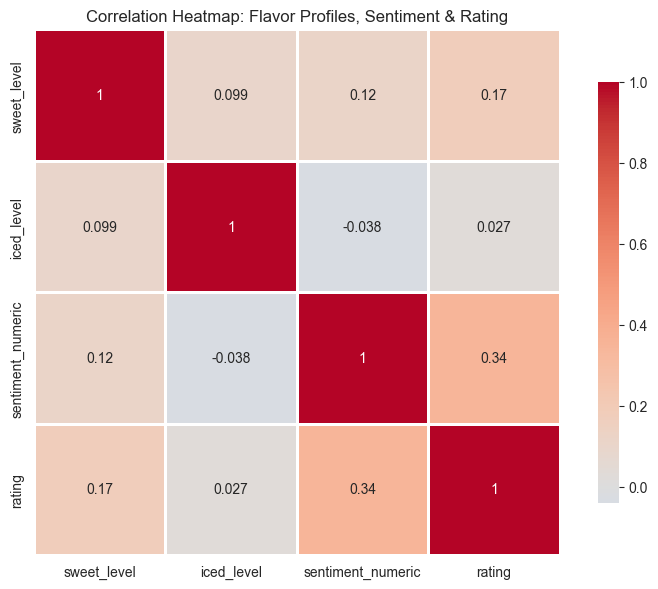

In [51]:
# Heatmap of correlations (CORRECTED)
plt.figure(figsize=(8, 6))
sns.heatmap(corr_combined, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap: Flavor Profiles, Sentiment & Rating')
plt.tight_layout()
plt.show()

In [52]:
# Create flavor profile segments (CORRECTED)
df_both['flavor_profile'] = pd.cut(df_both['sweet_level'], bins=[0, 2, 4], 
                                    labels=['Low Sweet', 'High Sweet']).astype(str) + ' / ' + \
                             pd.cut(df_both['iced_level'], bins=[0, 2, 4], 
                                    labels=['Low Iced', 'High Iced']).astype(str)

# Sentiment by flavor profile (CORRECTED)
flavor_sentiment = df_both.groupby('flavor_profile').agg({
    'sentiment_numeric': ['mean', 'std'],
    'Sentiment': lambda x: (x == 'positive').sum() / len(x) * 100,
    'Review': 'count',
    'rating': 'mean'
}).round(3)

flavor_sentiment.columns = ['Sentiment_Mean', 'Sentiment_Std', 'Percent_Positive', 'Count', 'Rating_Mean']
print("\nSentiment by Flavor Profile:")
print(flavor_sentiment)
print("\nNote: Sentiment_Mean ranges from -1 (all negative) to +1 (all positive)")


Sentiment by Flavor Profile:
                        Sentiment_Mean  Sentiment_Std  Percent_Positive  \
flavor_profile                                                            
High Sweet / High Iced           0.632          0.558            67.153   
High Sweet / Low Iced            0.672          0.524            69.858   
Low Sweet / High Iced            0.368          0.669            47.368   
Low Sweet / Low Iced             0.452          0.665            54.783   

                        Count  Rating_Mean  
flavor_profile                              
High Sweet / High Iced    684        4.768  
High Sweet / Low Iced     564        4.809  
Low Sweet / High Iced      94        4.547  
Low Sweet / Low Iced      115        4.304  

Note: Sentiment_Mean ranges from -1 (all negative) to +1 (all positive)


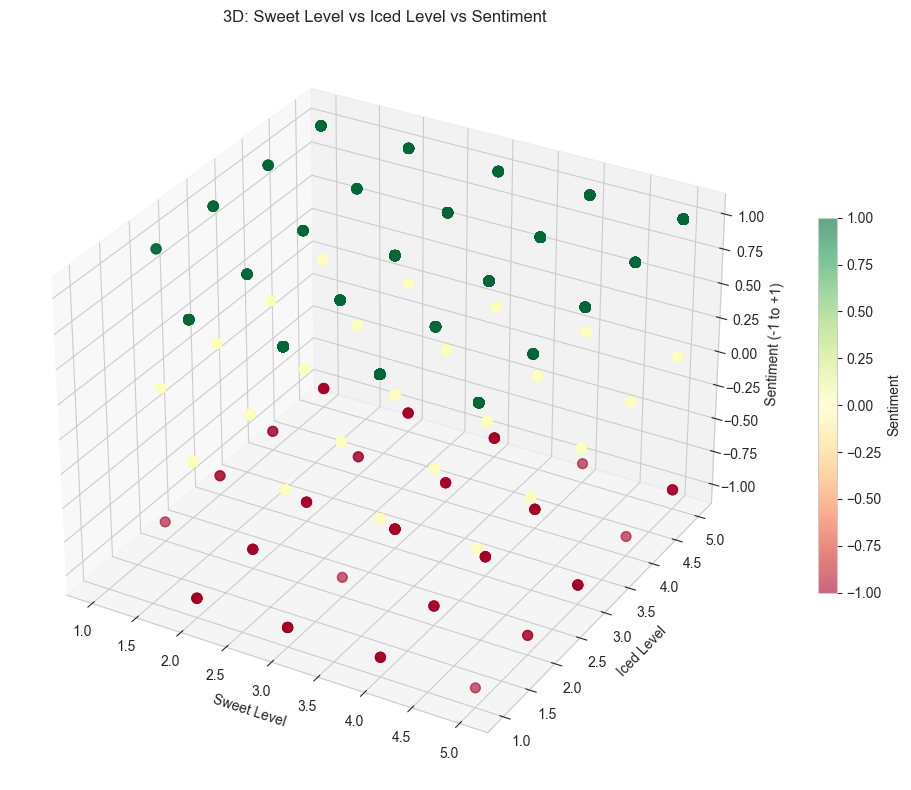

In [53]:
# 3D scatter plot (CORRECTED - using numeric sentiment)
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_both['sweet_level'], df_both['iced_level'], df_both['sentiment_numeric'],
                     c=df_both['sentiment_numeric'], cmap='RdYlGn', alpha=0.6, s=50, vmin=-1, vmax=1)

ax.set_xlabel('Sweet Level')
ax.set_ylabel('Iced Level')
ax.set_zlabel('Sentiment (-1 to +1)')
ax.set_title('3D: Sweet Level vs Iced Level vs Sentiment')
plt.colorbar(scatter, label='Sentiment', shrink=0.5)
plt.tight_layout()
plt.show()

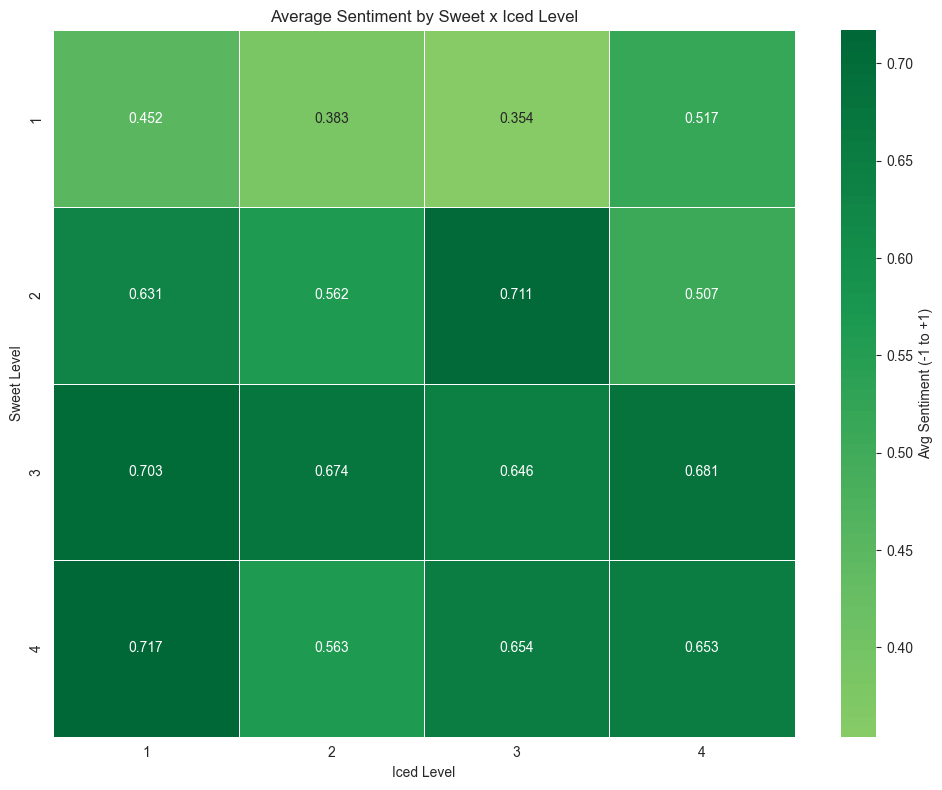

In [54]:
# 2D heatmap: average sentiment by sweet x iced bins (CORRECTED)
df_both['sweet_bin'] = pd.cut(df_both['sweet_level'], bins=4, labels=['1', '2', '3', '4'])
df_both['iced_bin'] = pd.cut(df_both['iced_level'], bins=4, labels=['1', '2', '3', '4'])

pivot_sentiment = df_both.pivot_table(values='sentiment_numeric',
                                       index='sweet_bin',
                                       columns='iced_bin',
                                       aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_sentiment, annot=True, fmt='.3f', cmap='RdYlGn',
            cbar_kws={'label': 'Avg Sentiment (-1 to +1)'}, linewidths=0.5, center=0)
plt.title('Average Sentiment by Sweet x Iced Level')
plt.xlabel('Iced Level')
plt.ylabel('Sweet Level')
plt.tight_layout()
plt.show()

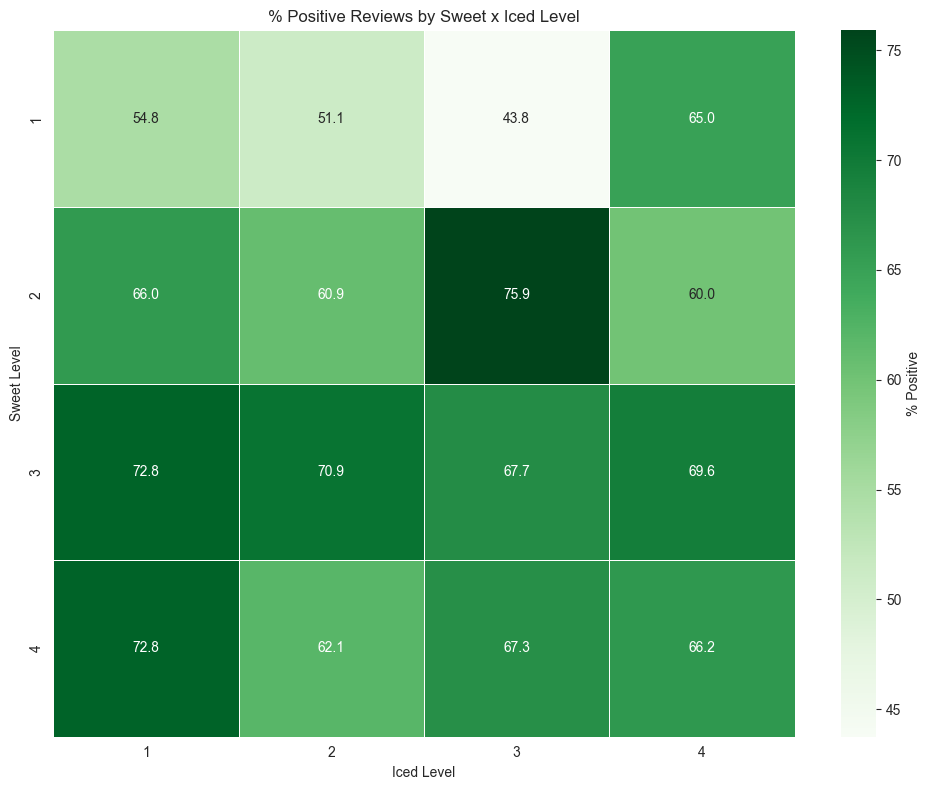

In [55]:
# Heatmap for percent positive (CORRECTED)
pivot_positive = df_both.pivot_table(values='Sentiment',
                                      index='sweet_bin',
                                      columns='iced_bin',
                                      aggfunc=lambda x: (x == 'positive').sum() / len(x) * 100)

plt.figure(figsize=(10, 8))
sns.heatmap(pivot_positive, annot=True, fmt='.1f', cmap='Greens',
            cbar_kws={'label': '% Positive'}, linewidths=0.5)
plt.title('% Positive Reviews by Sweet x Iced Level')
plt.xlabel('Iced Level')
plt.ylabel('Sweet Level')
plt.tight_layout()
plt.show()

## 7. Statistical Summary and Key Findings

In [56]:
print("\n" + "="*80)
print("SUMMARY OF KEY FINDINGS (CORRECTED)")
print("="*80)

print("\n1. REVIEW-LEVEL ANALYSIS")
print("-" * 40)

# Sweet
corr_sweet_rev, p_sweet_rev = stats.pearsonr(df_sweet['sweet_level'], df_sweet['sentiment_numeric'])
print(f"Sweet vs Sentiment:")
print(f"  - Correlation: {corr_sweet_rev:.4f} (p={p_sweet_rev:.4e})")
print(f"  - Sample size: {len(df_sweet)} reviews")
print(f"  - Interpretation: {'Significant' if p_sweet_rev < 0.05 else 'Not significant'}")

# Iced
corr_iced_rev, p_iced_rev = stats.pearsonr(df_iced['iced_level'], df_iced['sentiment_numeric'])
print(f"\nIced vs Sentiment:")
print(f"  - Correlation: {corr_iced_rev:.4f} (p={p_iced_rev:.4e})")
print(f"  - Sample size: {len(df_iced)} reviews")
print(f"  - Interpretation: {'Significant' if p_iced_rev < 0.05 else 'Not significant'}")

print("\n2. PRODUCT-LEVEL ANALYSIS")
print("-" * 40)

# Sweet
corr_sweet_prod, p_sweet_prod = stats.pearsonr(product_sweet['Sweet_Level_Avg'], 
                                                product_sweet['Sentiment_Numeric_Avg'])
print(f"Sweet vs Sentiment:")
print(f"  - Correlation: {corr_sweet_prod:.4f} (p={p_sweet_prod:.4e})")
print(f"  - Sample size: {len(product_sweet)} products")
print(f"  - Interpretation: {'Significant' if p_sweet_prod < 0.05 else 'Not significant'}")

# Iced
corr_iced_prod, p_iced_prod = stats.pearsonr(product_iced['Iced_Level_Avg'],
                                               product_iced['Sentiment_Numeric_Avg'])
print(f"\nIced vs Sentiment:")
print(f"  - Correlation: {corr_iced_prod:.4f} (p={p_iced_prod:.4e})")
print(f"  - Sample size: {len(product_iced)} products")
print(f"  - Interpretation: {'Significant' if p_iced_prod < 0.05 else 'Not significant'}")

print("\n3. COMBINED EFFECTS")
print("-" * 40)
print(f"Reviews with both sweet and iced: {len(df_both)}")
print(f"\nCorrelation summary:")
print(f"  - Sweet ↔ Iced: {corr_combined.loc['sweet_level', 'iced_level']:.4f}")
print(f"  - Sweet ↔ Sentiment: {corr_combined.loc['sweet_level', 'sentiment_numeric']:.4f}")
print(f"  - Iced ↔ Sentiment: {corr_combined.loc['iced_level', 'sentiment_numeric']:.4f}")
print(f"  - Rating ↔ Sentiment: {corr_combined.loc['rating', 'sentiment_numeric']:.4f}")

print("\n4. KEY DIFFERENCES FROM ORIGINAL ANALYSIS")
print("-" * 40)
print("Original analysis incorrectly used 'Sentiment Score' (confidence) as sentiment.")
print("This corrected version uses:")
print("  - Sentiment labels (positive/neutral/negative) for categorical analysis")
print("  - Numeric sentiment (-1/0/+1) for correlation analysis")
print("  - Percent positive as a key metric")
print("  - Sentiment Score only as a confidence measure, not sentiment polarity")

print("\n" + "="*80)


SUMMARY OF KEY FINDINGS (CORRECTED)

1. REVIEW-LEVEL ANALYSIS
----------------------------------------
Sweet vs Sentiment:
  - Correlation: 0.1166 (p=9.3099e-09)
  - Sample size: 2410 reviews
  - Interpretation: Significant

Iced vs Sentiment:
  - Correlation: -0.0385 (p=5.8858e-02)
  - Sample size: 2410 reviews
  - Interpretation: Not significant

2. PRODUCT-LEVEL ANALYSIS
----------------------------------------
Sweet vs Sentiment:
  - Correlation: 0.1667 (p=3.5468e-08)
  - Sample size: 1081 products
  - Interpretation: Significant

Iced vs Sentiment:
  - Correlation: -0.0789 (p=9.4198e-03)
  - Sample size: 1081 products
  - Interpretation: Significant

3. COMBINED EFFECTS
----------------------------------------
Reviews with both sweet and iced: 2410

Correlation summary:
  - Sweet ↔ Iced: 0.0995
  - Sweet ↔ Sentiment: 0.1166
  - Iced ↔ Sentiment: -0.0385
  - Rating ↔ Sentiment: 0.3434

4. KEY DIFFERENCES FROM ORIGINAL ANALYSIS
----------------------------------------
Original anal

## 8. Export Results

In [ ]:
# Create summary report (CORRECTED)
summary_data = {
    'Analysis': ['Review-Level Sweet', 'Review-Level Iced', 'Product-Level Sweet', 'Product-Level Iced'],
    'Correlation': [corr_sweet_rev, corr_iced_rev, corr_sweet_prod, corr_iced_prod],
    'P-Value': [p_sweet_rev, p_iced_rev, p_sweet_prod, p_iced_prod],
    'Sample_Size': [len(df_sweet), len(df_iced), len(product_sweet), len(product_iced)],
    'Significant': [p_sweet_rev < 0.05, p_iced_rev < 0.05, p_sweet_prod < 0.05, p_iced_prod < 0.05]
}
summary_df = pd.DataFrame(summary_data)

# Export
output_dir = 'results'
os.makedirs(output_dir, exist_ok=True)

summary_df.to_csv(f'{output_dir}/flavor_sentiment_summary_corrected.csv', index=False)
product_sweet.to_csv(f'{output_dir}/product_sweet_sentiment_corrected.csv', index=False)
product_iced.to_csv(f'{output_dir}/product_iced_sentiment_corrected.csv', index=False)

print(f"\nResults exported to {output_dir}/")
print(f"  - flavor_sentiment_summary_corrected.csv")
print(f"  - product_sweet_sentiment_corrected.csv ({len(product_sweet)} products)")
print(f"  - product_iced_sentiment_corrected.csv ({len(product_iced)} products)")

print("\n" + summary_df.to_string(index=False))


Results exported to results/
  - flavor_sentiment_summary_corrected.csv
  - product_sweet_sentiment_corrected.csv (1081 products)
  - product_iced_sentiment_corrected.csv (1081 products)

           Analysis  Correlation  P-Value  Sample_Size  Significant
 Review-Level Sweet        0.117    0.000         2410         True
  Review-Level Iced       -0.038    0.059         2410        False
Product-Level Sweet        0.167    0.000         1081         True
 Product-Level Iced       -0.079    0.009         1081         True


: 